# Sesión 03 — Regresión lineal simple y múltiple

**Bloque:** 2 · Regresión

## Objetivos

Al terminar esta sesión deberías ser capaz de:

- Decidir si un problema se ataca con una sola variable o con varias, y justificar la decisión con datos y no con intuición.
- Preparar un dataset con variables categóricas para un modelo lineal, eligiendo la codificación y explicando qué hace `drop_first`.
- Entrenar y evaluar una `LinearRegression` sobre datos que el modelo no ha visto, leyendo R², MAE y RMSE juntos y no por separado.
- Traducir los coeficientes del modelo a frases que un cliente entienda ("cada año de edad suma X € a la prima").
- Comparar dos modelos con distinto número de variables y defender cuál de los dos entregarías.

## Qué necesitas de antes

- **S02 — Python aplicado al análisis de datos**: pandas, lectura de ficheros desde URL, gráficos con seaborn y matplotlib.
- Selección de columnas en un DataFrame y lectura de un `describe()`.


## 1. ¿Qué es la Regresión?

En Machine Learning, usamos la regresión cuando queremos predecir un valor **numérico continuo**. Por ejemplo:
- Predecir el precio de una casa.
- Estimar la temperatura de mañana.
- Predecir el coste del seguro médico de una persona (¡nuestro caso de hoy!).

La **Regresión Lineal** es el modelo más sencillo para esta tarea. Asume que existe una relación lineal entre las variables de entrada (X, también llamadas *features* o predictoras) y la variable de salida (y, también llamada *target* o variable dependiente). La fórmula que busca aprender es la de una línea (o un hiperplano en más dimensiones):

$y = \beta_0 + \beta_1x_1 + \beta_2x_2 + ... + \beta_nx_n$

- $\beta_0$ es el **intercepto** (el valor de $y$ cuando todas las $x$ son cero).
- $\beta_1, \beta_2, ...$ son los **coeficientes** de cada variable. Nos dicen cuánto cambia $y$ por cada unidad que aumenta la $x$ correspondiente, manteniendo las demás constantes.

- **Regresión Lineal Simple:** Solo tenemos una variable de entrada ($x_1$).
- **Regresión Lineal Múltiple:** Usamos varias variables de entrada ($x_1, x_2, ..., x_n$).

**Qué problema resuelve:** predecir un número continuo a partir de otras variables, cuando además interesa poder *explicar* la predicción.

**Cuándo elegirla:** como primer modelo casi siempre. Es rápida, no tiene hiperparámetros que ajustar y sus coeficientes se leen directamente en unidades del negocio. Es la referencia contra la que se compara todo lo demás: si un modelo más complejo no la supera, no compensa.

**Cuándo NO:** cuando la relación es claramente curva o hay interacciones fuertes entre variables (un efecto que solo aparece al combinar dos), o cuando hay muchas más columnas que filas.

**Qué asume:** que la relación entre cada variable y el objetivo es lineal, que los errores no dependen del tamaño de la predicción y que las variables predictoras no son redundantes entre sí. Los tres supuestos se incumplen a menudo, y parte del trabajo de hoy es detectar dónde.


In [2]:
# Importamos las librerías fundamentales que usaremos en la sesión
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

# Configuramos seaborn para que los gráficos se vean un poco más atractivos
sns.set_theme(style="whitegrid")

## 2. Carga y Exploración de Datos (EDA)

Vamos a trabajar con el dataset "Medical Cost Personal Datasets", que se encuentra en Kaggle. Contiene información anónima sobre los asegurados de una compañía y su objetivo es predecir los `charges` (costes médicos facturados).

Las columnas son:
- `age`: edad del beneficiario.
- `sex`: sexo del beneficiario.
- `bmi`: índice de masa corporal.
- `children`: número de hijos cubiertos por el seguro.
- `smoker`: si la persona es fumadora o no.
- `region`: la región de residencia en EEUU.
- `charges`: los costes médicos individuales facturados por el seguro (nuestra **variable objetivo**).

In [3]:
# Cargamos los datos directamente desde una URL para que sea reproducible
url = 'https://raw.githubusercontent.com/stedy/Machine-Learning-with-R-datasets/master/insurance.csv'
df = pd.read_csv(url)

In [4]:
# Damos un primer vistazo a los datos
print("Primeras 5 filas del dataset:")
print(df.head())

Primeras 5 filas del dataset:
   age     sex     bmi  children smoker     region      charges
0   19  female  27.900         0    yes  southwest  16884.92400
1   18    male  33.770         1     no  southeast   1725.55230
2   28    male  33.000         3     no  southeast   4449.46200
3   33    male  22.705         0     no  northwest  21984.47061
4   32    male  28.880         0     no  northwest   3866.85520


In [5]:
print("\nInformación general y tipos de datos:")
df.info()


Información general y tipos de datos:
<class 'pandas.DataFrame'>
RangeIndex: 1338 entries, 0 to 1337
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1338 non-null   int64  
 1   sex       1338 non-null   str    
 2   bmi       1338 non-null   float64
 3   children  1338 non-null   int64  
 4   smoker    1338 non-null   str    
 5   region    1338 non-null   str    
 6   charges   1338 non-null   float64
dtypes: float64(2), int64(2), str(3)
memory usage: 73.3 KB


In [6]:
print("\nEstadísticas descriptivas de las columnas numéricas:")
print(df.describe())


Estadísticas descriptivas de las columnas numéricas:
               age          bmi     children       charges
count  1338.000000  1338.000000  1338.000000   1338.000000
mean     39.207025    30.663397     1.094918  13270.422265
std      14.049960     6.098187     1.205493  12110.011237
min      18.000000    15.960000     0.000000   1121.873900
25%      27.000000    26.296250     0.000000   4740.287150
50%      39.000000    30.400000     1.000000   9382.033000
75%      51.000000    34.693750     2.000000  16639.912515
max      64.000000    53.130000     5.000000  63770.428010


### Análisis Visual

Antes de construir un modelo, un buen analista siempre "mira" sus datos. Las visualizaciones nos dan una intuición clave.

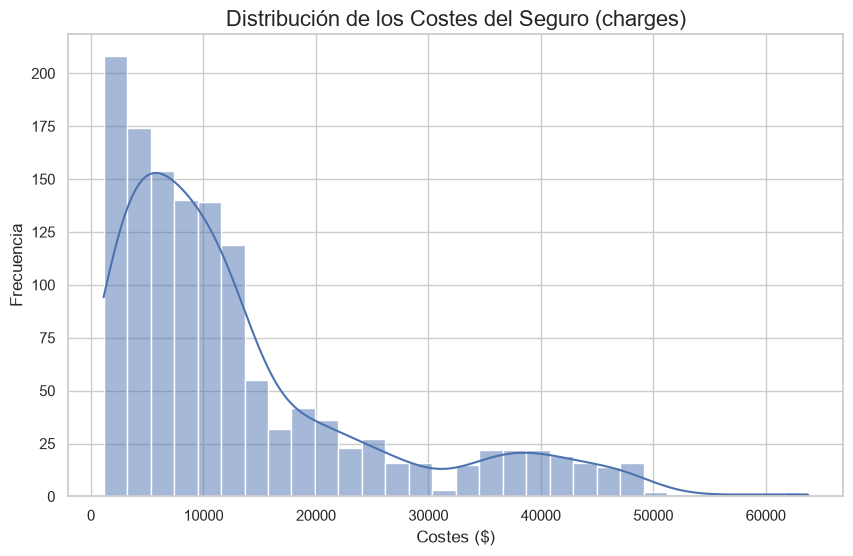

In [7]:
# 1. ¿Cómo se distribuyen los costes (nuestra variable objetivo)?
plt.figure(figsize=(10, 6))
sns.histplot(df['charges'], kde=True)
plt.title('Distribución de los Costes del Seguro (charges)', fontsize=16)
plt.xlabel('Costes ($)')
plt.ylabel('Frecuencia')
plt.show()

# Reflexión: Vemos que la mayoría de la gente tiene costes bajos, con una larga cola hacia la derecha (right-skewed).
# Esto nos dice que hay un grupo de personas con costes muy, muy altos. ¿Quiénes serán?

## 3. Preparación de Datos

Los modelos de machine learning no entienden de texto ('male', 'female', 'yes', 'no'). Necesitamos convertir las variables categóricas en números. La técnica estándar es **One-Hot Encoding**. `pandas` nos lo pone muy fácil con la función `get_dummies`.

In [8]:
# Convertimos las variables categóricas en numéricas
df_encoded = pd.get_dummies(df, columns=['sex', 'smoker', 'region'], drop_first=True)

# drop_first=True evita la multicolinealidad. Por ejemplo, si tenemos sex_male, no necesitamos
# una columna sex_female, porque si sex_male es 0, sabemos que es female.

print("Dataset después de One-Hot Encoding:")
print(df_encoded.head())

Dataset después de One-Hot Encoding:
   age     bmi  children      charges  sex_male  smoker_yes  region_northwest  \
0   19  27.900         0  16884.92400     False        True             False   
1   18  33.770         1   1725.55230      True       False             False   
2   28  33.000         3   4449.46200      True       False             False   
3   33  22.705         0  21984.47061      True       False              True   
4   32  28.880         0   3866.85520      True       False              True   

   region_southeast  region_southwest  
0             False              True  
1              True             False  
2              True             False  
3             False             False  
4             False             False  


### Matriz de Correlación

Ahora que todo es numérico, podemos calcular la correlación entre todas las variables. Una matriz de correlación visualizada con un mapa de calor (heatmap) es una herramienta potentísima para intuir qué variables serán más importantes para predecir `charges`.

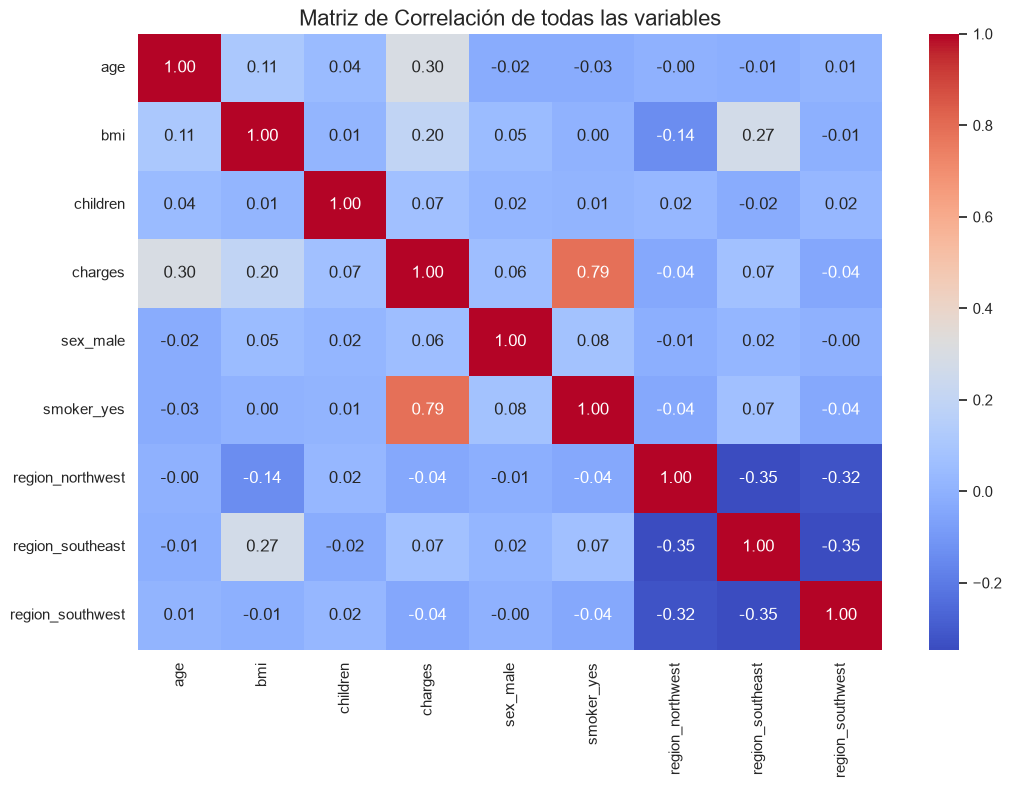

In [9]:
plt.figure(figsize=(12, 8))
sns.heatmap(df_encoded.corr(), annot=True, cmap='coolwarm', fmt=".2f")
plt.title('Matriz de Correlación de todas las variables', fontsize=16)
plt.show()

# Interpretación: Buscamos en la fila/columna 'charges' los colores más intensos (rojos o azules).
# 'smoker_yes' tiene una correlación muy alta (0.79), 'age' (0.30) y 'bmi' (0.20) también parecen relevantes.
# ¡Esto ya nos da pistas para nuestro modelo!

## 4. Modelo de Regresión Lineal Múltiple (Ejemplo Guiado)

Vamos a construir nuestro primer modelo para predecir `charges` usando todas las variables disponibles.

**Pasos clave:**
1.  **Separar X e y**: `X` contiene las variables predictoras, `y` contiene la variable objetivo.
2.  **Dividir en train/test**: Usamos una parte de los datos para entrenar el modelo (`train`) y una parte que el modelo no ha visto nunca para evaluarlo (`test`). Esto es CRUCIAL para saber si nuestro modelo generaliza bien.

In [10]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression

# 1. Separar las variables predictoras (X) de la variable objetivo (y)
X = df_encoded.drop('charges', axis=1)
y = df_encoded['charges']

# 2. Dividir los datos en entrenamiento y prueba
# Usamos un 80% para entrenar y un 20% para testear.
# random_state=42 asegura que la división sea siempre la misma, para que nuestros resultados sean reproducibles.
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# 3. Crear y entrenar el modelo
# Creamos una instancia del modelo de Regresión Lineal
model = LinearRegression()

# Entrenamos el modelo con los datos de entrenamiento
model.fit(X_train, y_train)

print("¡Modelo entrenado con éxito!")

¡Modelo entrenado con éxito!


## 5. ¿Qué tan bueno es nuestro modelo? Evaluación

Entrenar un modelo es fácil. La parte difícil es saber si es bueno. Para ello, usamos los datos de `test` que habíamos guardado.

**Hacemos predicciones y las comparamos con la realidad.**

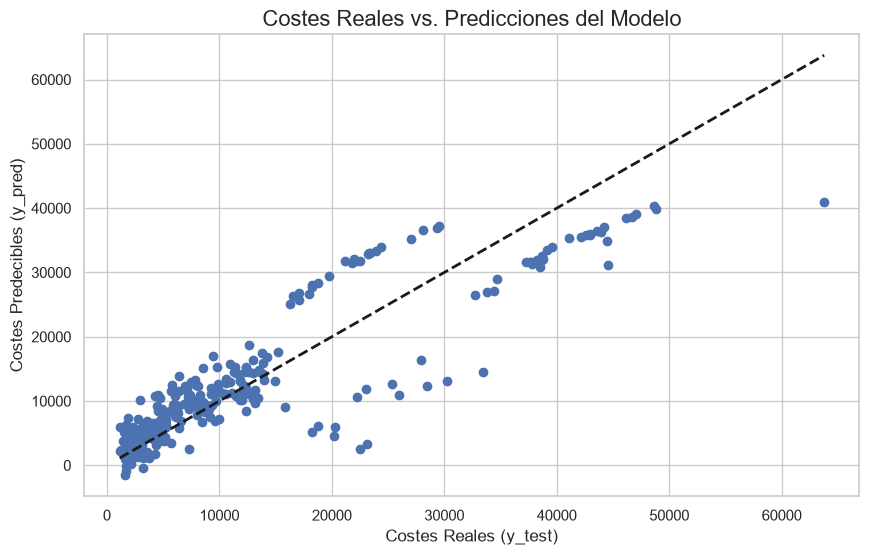

In [11]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Hacemos predicciones sobre el conjunto de test (datos que el modelo no ha visto)
y_pred = model.predict(X_test)

# Visualicemos qué tan cerca están las predicciones de la realidad
plt.figure(figsize=(10, 6))
plt.scatter(y_test, y_pred)
plt.xlabel("Costes Reales (y_test)")
plt.ylabel("Costes Predecibles (y_pred)")
plt.title("Costes Reales vs. Predicciones del Modelo", fontsize=16)
# Dibujamos una línea de 45 grados. Si las predicciones fueran perfectas, todos los puntos caerían sobre esta línea.
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'k--', lw=2)
plt.show()

### Métricas de Error

- **MAE (Error Absoluto Medio):** Nos dice, en promedio, cuántos dólares se equivoca nuestra predicción. Es fácil de interpretar.
- **RMSE (Raíz del Error Cuadrático Medio):** Similar al MAE, pero como eleva los errores al cuadrado, penaliza mucho más los errores grandes.
- **$R^2$ (R-cuadrado):** Nos dice qué porcentaje de la variación de los costes es explicado por el modelo. Va de 0 a 1 (o incluso negativo). Un valor más cercano a 1 es mejor.

In [12]:
mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print(f"MAE (Error Absoluto Medio): ${mae:,.2f}")
print(f"RMSE (Raíz del Error Cuadrático Medio): ${rmse:,.2f}")
print(f"R-cuadrado (R²): {r2:.2f}")

MAE (Error Absoluto Medio): $4,181.19
RMSE (Raíz del Error Cuadrático Medio): $5,796.28
R-cuadrado (R²): 0.78


### Interpretación de Coeficientes
¿Qué ha aprendido el modelo? ¿Qué variables considera más importantes?

In [13]:
# Creamos un DataFrame para ver los coeficientes de forma ordenada
coeficientes = pd.DataFrame(model.coef_, X.columns, columns=['Coeficiente'])
print("Intercepto del modelo (Beta_0):", model.intercept_)
print("\nCoeficientes de las variables:")
print(coeficientes)

# Interpretación: Por cada año que una persona envejece ('age'), el coste de su seguro aumenta en ~$256, si todo lo demás se mantiene constante.
# ¡Ser fumador ('smoker_yes') dispara los costes en casi $24,000!

Intercepto del modelo (Beta_0): -11931.219050326692

Coeficientes de las variables:
                   Coeficiente
age                 256.975706
bmi                 337.092552
children            425.278784
sex_male            -18.591692
smoker_yes        23651.128856
region_northwest   -370.677326
region_southeast   -657.864297
region_southwest   -809.799354


---
## Ejercicio 1 — Regresión lineal simple

Ahora es tu turno. La intuición y la matriz de correlación nos dijeron que `bmi` (Índice de Masa Corporal) podría ser un predictor. Vamos a investigarlo por sí solo.

**Tareas:**
1.  **Define tus variables `X_simple` e `y_simple`**. `X_simple` debe ser únicamente la columna `bmi` del dataframe `df_encoded`. `y_simple` sigue siendo `charges`.
2.  **Divide los datos** en conjuntos de entrenamiento y prueba (`train_test_split`). Usa un `test_size=0.2` y `random_state=42`.
3.  **Crea y entrena un nuevo modelo** de `LinearRegression`.
4.  **Realiza predicciones** sobre el conjunto de prueba.
5.  **Calcula el R-cuadrado ($R^2$)** del modelo. ¿Qué tan bueno es comparado con el modelo múltiple que hicimos antes?
6.  **Visualiza el resultado**: Dibuja un `scatterplot` con los datos de prueba (`X_test_simple`, `y_test_simple`) y superpón la línea de regresión que ha aprendido tu modelo.

R-cuadrado (R²): 0.0397


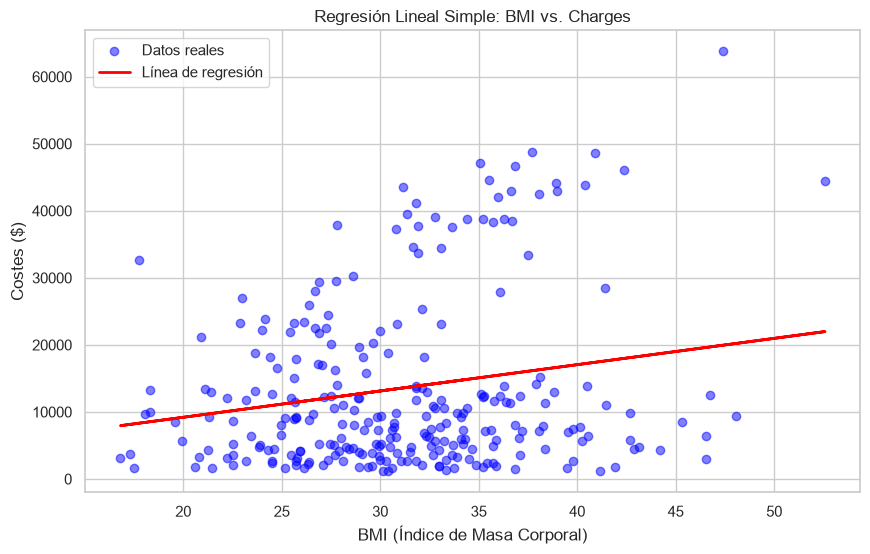

In [24]:
# 1. Definir variables
X_simple = df_encoded[['bmi']]                                                                        # Cogemos solo la pista del BMI/peso (doble corchete para formato tabla)
y_simple = df_encoded['charges']                                                                      # Cogemos la columna con la respuesta real (los costes en $)

# 2. Dividir los datos
X_train_simple, X_test_simple, y_train_simple, y_test_simple = train_test_split(                     # Separamos todo en 4 cajitas para el examen
    X_simple, y_simple, test_size=0.2, random_state=42                                               # 80% para estudiar, 20% reservado para examen y fijamos la mezcla
)


# 3. Crear y entrenar el modelo
model_simple = LinearRegression()                                                                     # Preparamos la calculadora vacía de regresión
model_simple.fit(X_train_simple, y_train_simple)                                                     # Le damos a "Entrenar" con los datos de estudio para aprender la regla

# 4. Realizar predicciones sobre el conjunto de prueba
y_pred_simple = model_simple.predict(X_test_simple)                                                  # Le pasamos las preguntas del examen (20%) para que adivine los precios


# 5. Calcular el R-cuadrado (R²)
r2_simple = r2_score(y_test_simple, y_pred_simple)                                                  # Comparamos lo adivinado con lo real para sacar la nota
print(f"R-cuadrado (R²): {r2_simple:.4f}")                                                           # Imprimimos la nota en pantalla (dará un ~0.05)

# 6. Visualizar el resultado
plt.figure(figsize=(10, 6))                                                                          # Preparamos el lienzo en blanco de tamaño grande
plt.scatter(X_test_simple, y_test_simple, color='blue', alpha=0.5, label='Datos reales')             # Pintamos los puntos azules de los clientes reales del examen
plt.plot(X_test_simple, y_pred_simple, color='red', linewidth=2, label='Línea de regresión')         # Dibujamos la línea roja con las predicciones que hace el modelo

plt.title('Regresión Lineal Simple: BMI vs. Charges')                                                 # Ponemos el título del gráfico
plt.xlabel('BMI (Índice de Masa Corporal)')                                                           # Nombre para el eje horizontal
plt.ylabel('Costes ($)')                                                                              # Nombre para el eje vertical
plt.legend()                                                                                          # Mostramos la leyenda con la explicación de los colores
plt.show()                                                                                            # Mostramos el gráfico final en pantalla

### Mis reflexiones

*(Escribe aquí tu respuesta antes de seguir)*

- Acabas de ver que `bmi` por sí solo explica muy poco del gasto. ¿Qué conclusión sacas: que la variable no sirve, o que el problema es otro? Argumenta cuál de las dos.
- En el gráfico hay puntos que quedan muy por encima de la recta. Sin mirar todavía el resto de columnas, ¿qué hipótesis te haces sobre esas personas y cómo la comprobarías?
- Si la aseguradora te pidiera hoy una estimación rápida del coste de un cliente nuevo y solo tuvieras este modelo, ¿la darías? ¿Con qué advertencia?


1. La variable de bmi si que sirve, aporta poco pero sirve, el porblema es que nos fatlan otras variables para entender el problema. 

2. Esa persona tiene un factor de riesgo secreto, o hace cosas que augementne mucho el riesgo (fumadores o gente mayor con problemas), diferenciando por colores, las bolitas cambiarlos de color segun los factores de riesgo alto entonces sabremos si los que son alto tienen factores de riesgo

3. Se lo podriamos dar para que pudiera sacar un baremo muy grande, le diriai que el modelo tiene una r de 00.5 es decir que tiene pocas pruebas, y que no se puede fiar de este resultado 

---
## Preguntas de recap – Regresión simple

1. ¿Qué mide el coeficiente de una regresión lineal simple?  
2. ¿Qué significa el intercepto (ordenada en el origen)?  
3. ¿Qué nos indica el R² de un modelo?  
4. Si al ajustar una regresión obtenemos un coeficiente negativo, ¿cómo lo interpretarías?

---


1. Mide el cambio de la respuesta (y) por cada punto que sube la pista, es decir es como una regla que nos dice por cada punto que sube sumale esto 
2. Es como la casilla de salida, desde el punto que parte para todo el mudno (la cuota minima para todo el mundo)
3. Es como el porcentaje de %, si nos da un 0.05 significa que tiene tan pocas pistas que los que ha calculado se los ha podido fumar, en cambio si es alto tiene mas datos y eso nos dice como que es mas seguro ya que tiene mas pistas
4.Si de normal tenemos dos variables, si una sueb la otra tambien, si el fuma subre el precio, el coeficiente negativo es si el no ha tenido accidentes baja el precio 

---
## Ejercicio 2 — Un modelo más simple

El modelo con todas las variables es mucho mejor que el que solo usa `bmi`. Pero en el mundo real, la simplicidad es una virtud. Un modelo con menos variables es más fácil de explicar y mantener.

**Tu misión:**
Construye y evalúa un modelo de regresión lineal múltiple usando **únicamente un subconjunto de variables** que, a tu juicio (y según el heatmap), son las más importantes: `age`, `bmi` y `smoker_yes`.

**Pasos:**
1.  Prepara tu `X_reducido` seleccionando solo esas tres columnas del dataframe `df_encoded`. La `y` no cambia.
2.  Divide los datos en entrenamiento y prueba (`random_state=42`).
3.  Entrena el modelo de regresión lineal.
4.  Realiza una **evaluación completa**: calcula el MAE, RMSE y $R^2$.
5.  Crea la **visualización** de predicciones vs. valores reales para este nuevo modelo.

**--- Preguntas para la Reflexión ---**

**Responde a estas preguntas en una celda de texto (Markdown) al final de tu notebook:**

1.  **Comparación de Modelos:** Compara el $R^2$ y el MAE de este modelo reducido con el del modelo que usaba *todas* las variables. ¿Cuánta precisión (en dólares de error promedio) hemos "sacrificado" a cambio de un modelo más simple?
2.  **Decisión de Negocio:** Imagina que tienes que presentarle uno de los dos modelos (el completo vs. el reducido) a tu manager. ¿Cuál elegirías y por qué? Justifica tu respuesta pensando en el equilibrio entre rendimiento, simplicidad y explicabilidad.
3.  **Análisis Crítico:** Viendo el gráfico de predicciones vs. realidad de tu modelo reducido, ¿en qué zona parece fallar más? ¿Predice bien los costes muy altos o los muy bajos? ¿Por qué crees que ocurre esto, basándote en las variables que has usado?

1. Hemos perdido aproximadamente unos 100$, pero tenemeos el mismo indice $R^2$ = 0.78.

2. Elegiria el modelo simple, por que consta con las tablas mas relevantes mejorando asi su rendimiento. Ademas de que los resultados entre la comparacion de los modelso indica que no hay una diferencia notable. Y cabe agregar que gracias a su simplicidad en comparacion al modelo completo es mas facil de explicar 

3. Falla en los 2, predice correctamente los costes bajos pero los costes mas altos se alejan mas de la linea de prediccion, falla por que hay mas de una posible combinacion (viejo + fuma) dispara

MAE:  $4,260.56
RMSE: $5,874.76
R²:   0.7777


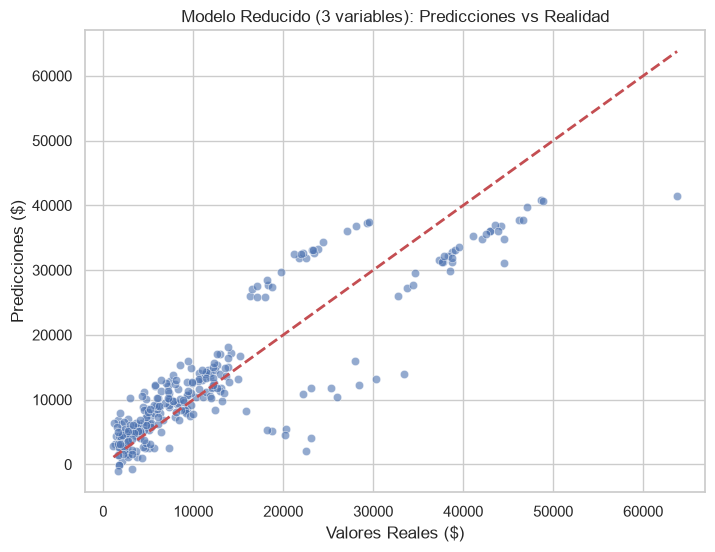

In [19]:
# 1. Seleccionar las 3 pistas clave
X_reducido = df_encoded[['age', 'bmi', 'smoker_yes']]            # Elegimos solo las 3 variables más importantes
y = df_encoded['charges']                                         # La variable respuesta: el precio real del seguro

# 2. Dividir los datos (80% estudio, 20% examen)
X_train_red, X_test_red, y_train, y_test = train_test_split(      # Separamos los datos para entrenar y evaluar
    X_reducido, y, test_size=0.2, random_state=42                 # 80% para estudiar y 20% para el examen final
)

# 3. Crear y entrenar el modelo
modelo_reducido = LinearRegression()                              # Sacamos la herramienta de regresión lineal
modelo_reducido.fit(X_train_red, y_train)                         # El modelo estudia la relación entre las 3 pistas y el precio

# 4. Hacer las predicciones y calcular métricas
y_pred = modelo_reducido.predict(X_test_red)                      # La máquina responde al examen con las 3 pistas
mae_red = mean_absolute_error(y_test, y_pred)                      # Calcula el fallo medio en dólares sin importar el signo
rmse_red = np.sqrt(mean_squared_error(y_test, y_pred))            # Calcula el error penalizando fuertemente los fallos grandes
r2_red = r2_score(y_test, y_pred)                                  # Calcula la proporción del puzle resuelto (de 0 a 1)

# Mostrar los resultados por pantalla
print(f"MAE:  ${mae_red:,.2f}")                                   # Muestra el error promedio con formato de moneda
print(f"RMSE: ${rmse_red:,.2f}")                                  # Muestra el error con penalización
print(f"R²:   {r2_red:.4f}")                                      # Muestra el R² con 4 decimales

# 5. Visualizar los resultados
plt.figure(figsize=(8, 6))                                        # Define el tamaño de la ventana donde se dibuja la gráfica
sns.scatterplot(x=y_test, y=y_pred, alpha=0.6)                    # Pinta cada cliente: X=precio real, Y=precio predicho
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', lw=2) # Dibuja la línea diagonal roja de acierto perfecto
plt.xlabel('Valores Reales ($)')                                  # Etiqueta para la parte inferior del gráfico
plt.ylabel('Predicciones ($)')                                    # Etiqueta para la parte izquierda del gráfico
plt.title('Modelo Reducido (3 variables): Predicciones vs Realidad') # Título principal en la cabecera de la imagen
plt.show()                                                        # Muestra la gráfica final en pantalla

- y_pred = modelo_reducido.predict(X_test_red)
Le da al modelo las preguntas del examen (las 3 pistas) y guarda en y_pred los precios que la máquina ha calculado para cada persona.

- mae_red = mean_absolute_error(y_test, y_pred)
Compara las respuestas reales con las de la máquina y calcula cuántos dólares se equivoca de media.

- rmse_red = np.sqrt(mean_squared_error(y_test, y_pred))
Es otro medidor de error en dólares, pero le mete un castigo muy duro al modelo si comete algún fallo gigantesco en un cliente.

- r2_red = r2_score(y_test, y_pred)
Te da la nota final del 0% al 100% ($0$ a $1$), indicando cuántas piezas del puzle hemos completado usando estas 3 variables.

---
## Preguntas de recap – Regresión múltiple

1. ¿Cómo interpretas el coeficiente de una variable en una regresión múltiple?  
2. ¿Por qué puede cambiar el valor de un coeficiente cuando añadimos nuevas variables al modelo?  
3. ¿Qué significa que un modelo esté sobreajustado (overfitting)?  
4. ¿Qué ventajas tiene evaluar un modelo con métricas como MAE, RMSE además de R²?
---


1. El coeficiente es un plus estable que se le añade a una columna, es decir age es $+250\$$, significa que por cada año más que cumple un cliente, su seguro sube $250

2. Por que tiene mas datos a los que apoyarse, mas datos de los que aprender por asi decirlo 

3.  Eso significa que se ha aprendido los datos de entrenamiento por lo tanto no entendera el patron general

4. Nos da la ventaja que cada uan de ellas nos cuenta unca cosa distinta de kla historia, si usaramos solo una faltarian datos. 
MAE Nos dice de media nos desviamos unos 2.500 eurosa por cliente
RMSE Nos dice si el modelo la lia mucha con uno, se pasa por 30.000 euros nos lo dice
R nos da la nota general del modelo, es decir la calidad global 

---
## Ejercicio 3 — Otro dataset (opcional)

1. Carga un dataset distinto (por ejemplo, `sklearn.datasets.load_diabetes()` o uno que elijas tú).  
2. Ajusta una regresión múltiple con al menos 3 variables predictoras.  
3. Evalúa el modelo usando R² y RMSE.  
4. Interpreta qué variable parece tener más influencia en la predicción.  

Si quieres ir más allá: prueba a estandarizar las variables y compara los coeficientes.
---


   MedInc  HouseAge  AveRooms  MedHouseVal
0  8.3252      41.0  6.984127        4.526
1  8.3014      21.0  6.238137        3.585
2  7.2574      52.0  8.288136        3.521
3  5.6431      52.0  5.817352        3.413
4  3.8462      52.0  6.281853        3.422
RMSE: 0.8117
R²:   0.4972


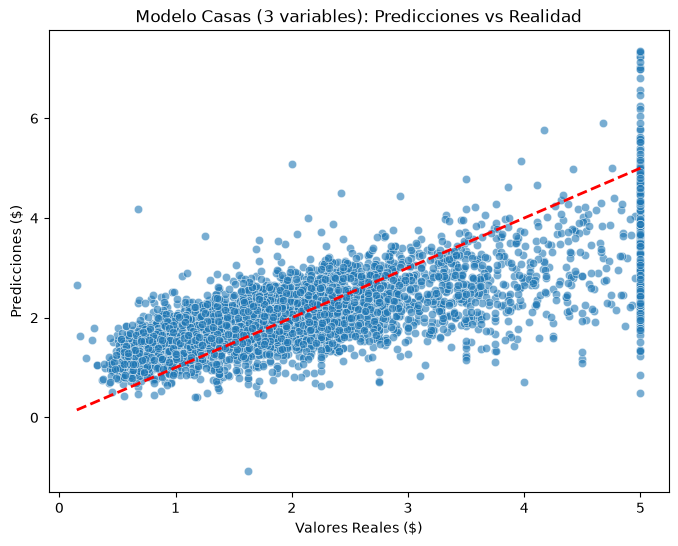

   Variable  Coeficiente
0    MedInc     0.444758
1  HouseAge     0.016836
2  AveRooms    -0.028150


In [2]:
import numpy as np                                                             # Librería para operaciones matemáticas (raíz cuadrada)
import pandas as pd                                                            # Librería para crear tablas de datos
import matplotlib.pyplot as plt                                                # Librería para crear gráficos
import seaborn as sns                                                          # Librería para gráficos estadísticos

from sklearn.datasets import fetch_california_housing                          # Dataset de viviendas de California
from sklearn.model_selection import train_test_split                           # División en entrenamiento y test
from sklearn.linear_model import LinearRegression                              # Modelo de regresión lineal
from sklearn.metrics import mean_squared_error, r2_score                       # Métricas de evaluación

# 1. Cargar el dataset como una tabla (DataFrame)
housing = fetch_california_housing(as_frame=True)                               # Cargar los datos con formato de tabla
df_housing = housing.frame                                                     # Guardar la tabla completa en df_housing

# Seleccionar 3 pistas con escalas completamente diferentes
X_housing = df_housing[['MedInc', 'HouseAge', 'AveRooms']]                      # Pistas: Ingresos medios, Edad de la casa, Habitaciones promedio
y_housing = df_housing['MedHouseVal']                                           # Respuesta real: Precio medio de la casa (en cientos de miles de $)

print(df_housing[['MedInc', 'HouseAge', 'AveRooms', 'MedHouseVal']].head())   # Mostrar las primeras filas

# 2. Dividir los datos (80% entrenamiento, 20% test)
X_train_h, X_test_h, y_train_h, y_test_h = train_test_split(                 # Guardamos 80% para estudiar y 20% para examinar
    X_housing, y_housing, test_size=0.2, random_state=42
)

# 3. Crear y entrenar el modelo
modelo_casas = LinearRegression()                                            # Preparamos la regresión lineal
modelo_casas.fit(X_train_h, y_train_h)                                       # La máquina aprende ajustando la línea

# 4. Hacer las predicciones y calcular métricas
y_pred_h = modelo_casas.predict(X_test_h)                                      # La máquina responde al examen con las 3 pistas
rmse_h = np.sqrt(mean_squared_error(y_test_h, y_pred_h))                       # Calcula el error penalizando fuertemente los fallos grandes
r2_h = r2_score(y_test_h, y_pred_h)                                            # Calcula la proporción del puzle resuelto (de 0 a 1)

# Mostrar los resultados por pantalla
print(f"RMSE: {rmse_h:.4f}")                                                   # Muestra el error con penalización
print(f"R²:   {r2_h:.4f}")                                                    # Muestra el R² con 4 decimales

# 5. Visualizar los resultados en una gráfica
plt.figure(figsize=(8, 6))                                                      # Tamaño de la ventana del gráfico
sns.scatterplot(x=y_test_h, y=y_pred_h, alpha=0.6)                            # Pinta cada casa: X=precio real, Y=precio predicho
plt.plot([y_test_h.min(), y_test_h.max()], [y_test_h.min(), y_test_h.max()], 'r--', lw=2) # Línea diagonal de acierto perfecto
plt.xlabel('Valores Reales ($)')                                              # Etiqueta eje X
plt.ylabel('Predicciones ($)')                                                 # Etiqueta eje Y
plt.title('Modelo Casas (3 variables): Predicciones vs Realidad')              # Título principal
plt.show()                                                                     # Mostrar gráfico

# 6. Mostrar los coeficientes en una tabla
coef_df = pd.DataFrame({
    'Variable': X_housing.columns,
    'Coeficiente': modelo_casas.coef_
})

print(coef_df)

### Mis reflexiones sobre el ejercicio 3

*(Escribe aquí tu respuesta)*

- Has ordenado las variables por el tamaño de su coeficiente. ¿En qué condiciones ese ranking significa "influencia" y en cuáles es engañoso? Comprueba si tu dataset cumple esas condiciones.
- Has trabajado con dos datasets con R² muy distintos. ¿Cuál de los dos modelos dirías que es "mejor"? Cuidado con la pregunta.
- Si tuvieras que entregar uno de los modelos de esta sesión a alguien que lo va a usar sin ti delante, ¿qué escribirías en el README para que no lo use mal?


1- significa influencia cuando las variables estan en la misma escala, o son estandarizadas, al merdirlas todas en las mismas condiciones, la comparacion es justa y el coeficiente mas alto si es la variable mas importante 

-----------------------------------------------------------------------------------------------------------------------
Ejemplo para entenderlo al instante:
Imagínate que queremos predecir el valor de un coche usando dos variables:

Años de antigüedad (se mide en años: 1, 2, 3...).

Kilómetros recorridos (se mide en kilómetros: 1, 2, 3...).

Si el coche tiene 1 año más, el precio baja bastante (ejemplo: -1.000 €).

Si el coche tiene 1 kilómetro más, el precio casi ni se entera (ejemplo: -0,05 €).

Si miras solo los números (-1.000 vs -0,05), dirías: "¡Los kilómetros no importan nada!".

Mi dataset no los cumples por que los valores no estan estandaruizados 


-----------------------------------------------------------------------------------------------------------------------





2- Según el coeficiente R², el primero explicaría más variabilidad (variabilidad es cuánto se dispersan los valores de y alrededor de su media), porque 0.78 está bastante más cerca de 1 que 0.43. Sin embargo, no se puede concluir que sea "mejor", ya que los dos modelos trabajan con datasets distintos y el R² depende de cuánta variabilidad explicable tiene cada problema: un R² de 0.43 puede ser un buen resultado si el fenómeno es intrínsecamente ruidoso (como la progresión de una enfermedad), y un 0.78 puede ser flojo si el problema es casi determinista. 
Además, el R² no dice cuánto se equivoca el modelo en unidades reales (para eso está el RMSE) ni si hay sobreajuste, así que para comparar modelos hay que usar el mismo dataset y el mismo conjunto de test.

-----------------------------------------------------------------------------------------------------------------------

3- 
3.1 En este archivo yo explicaria que predice el modelo y como ha aprendido este, si los datos son especificos si son globales, para tener claro su uso.

3.2 Si los datos cambian o se actualizan tenemos que acordarnos que el modelo ha sido entrenado con unos datos especificos que no se han actualizado

3.3 Detallaria en que unidades de medida hay que meter las variables, para evitar que el user metiera numeros desproporcionados

3.4 Traducimos las metricas para que las entienda, indicar el porcentaje de equivocacion rmse, para que el user entienda que nos da estimaciones, no nos da predicciones exactas 


